Checking busbar current capabilities vs pack fuse current capability

Specific heat capacity of air: 1005 J/kgK --> at constant pressure

Volume of air on top of enclosure: m3

mass of air: at 35 C

    1.146 kg/m3

In [13]:
air_rho = 1.146         # kg/m3
air_c = 1005            # J/kgK
l = 635 * 10**-3        # m
h = 63.5 * 10**-3       # m
w = 388.3 * 10**-3      # m
b = 462 * 10**-3        # m
a = 287 * 10**-3        # m
h_trap = 47 * 10**-3    # m
A_trap = (b + a) / 2 * h    # m
A_tot = l * h - A_trap
V_tot = A_tot * w
V_tot   # TOTAL VOLUME OF AIR IN M3

air_mass = V_tot * air_rho  # kg
air_mass # 7 grams seems pretty reasonable

0.007360943107650001

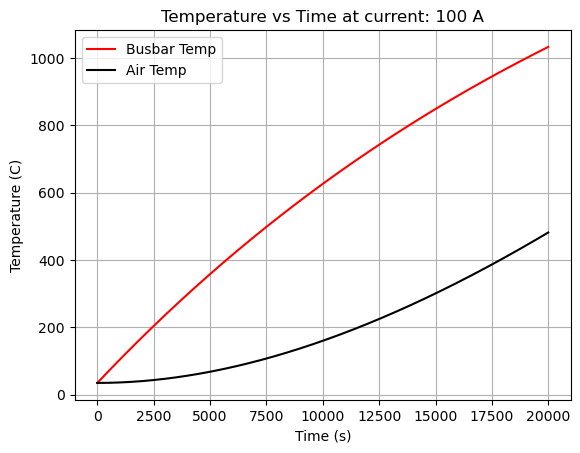

1033.2118000745509


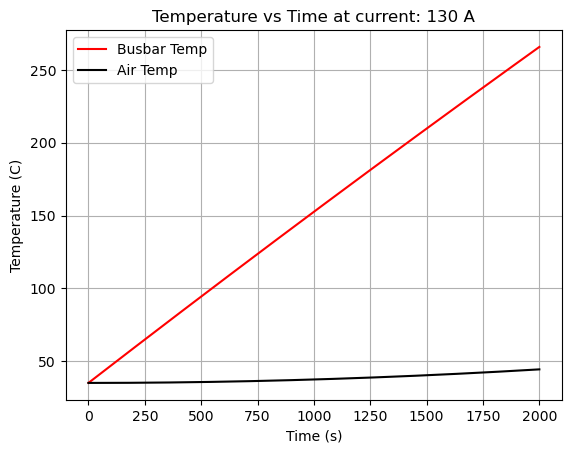

265.84848684543795


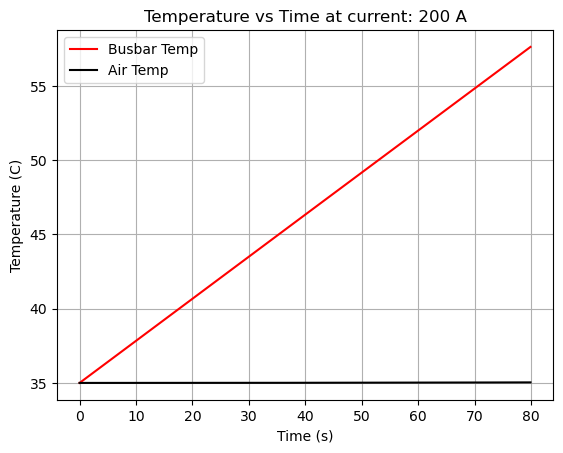

57.622173234672985


In [14]:
import numpy as np
import matplotlib.pyplot as plt

temp_0 = 35                 # C - initial temp
thickness = 3.18 * 10**-3   # m - thickness
width = 12.7 * 10**-3       # m - width
length = 80 * 10**-3     # m - length
Ax = thickness * width      # m2 - cross sectional area
As = 2 * thickness * length + 2 * thickness * width # m2 - cross sectional area
rho_R = 2.82*10**-8         # Ohm-m - resistivity of aluminum
rho_M = 2710                # kg/m3 - mass density of aluminum
c = 900                     # J/kgK - specific heat capacity
h_free = 0.5                # low heat output
dt = 0.1                    # seconds - time step

current = np.array([100, 130, 200])             # A
t_max = np.array([20000, 2000, 80])             # seconds
resistance = rho_R / Ax * length                # Ohm
mass = rho_M * Ax * length                      # kg

for j in range(0, len(current)):

    busTemp = [temp_0]
    Q_out = []
    air_temp = [temp_0]
    time = np.arange(0, t_max[j], dt)                  # s - time step
    Q_gen = resistance * current[j]**2                 # W

    for i in range(0, len(time) - 1):
        Q_out.append(h_free * As * (busTemp[i] - air_temp[0]))              # W - heat out to air
        busTemp.append((Q_gen - Q_out[i]) * dt / (mass * c) + busTemp[i])   # C - busbar temperature
        air_temp.append(Q_out[i] * dt / (air_mass * air_c) + air_temp[i])   # C - air temperature

    # Then output to graph
    Q_out_ar = np.array(Q_out)
    busTemp_ar = np.array(busTemp)

    plt.plot(time, busTemp_ar, 'r', label="Busbar Temp")
    plt.plot(time, air_temp, 'k', label="Air Temp")
    plt.title(("Temperature vs Time at current: " + str(current[j]) + " A"))
    plt.grid(True)
    plt.legend()
    plt.xlabel("Time (s)")
    plt.ylabel("Temperature (C)")
    plt.show()

    print(busTemp[-1])